# Preparation

In [1]:
import pandas as pd

df = pd.read_csv('gdp_and_crime.csv')

In [2]:
df.dtypes

year                   int64
district              object
crimes                 int64
gdp_purchasers         int64
gdp_agriculture      float64
gdp_manufacturing    float64
gdp_services         float64
dtype: object

In [3]:
len(df.district.unique()) 

118

In [4]:
df.district.value_counts()

district
Alor Gajah    10
Pasir Mas     10
Rompin        10
Rembau        10
Raub          10
              ..
Klang         10
Kerian        10
Keningau      10
Kemaman       10
Yan           10
Name: count, Length: 118, dtype: int64

In [5]:
df.describe()

,year,crimes,gdp_purchasers,gdp_agriculture,gdp_manufacturing,gdp_services
count,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000,1180.000000
mean,2019.500000,409.148305,7878.224576,688.677876,2280.084780,4429.858879
std,2.873499,659.463532,18458.771185,626.941554,6121.720644,11674.859993
min,2015.000000,1.000000,104.000000,16.829047,0.000000,47.402400
25%,2017.000000,75.750000,916.750000,268.789220,29.006638,466.630275
50%,2019.500000,186.000000,2097.500000,453.373263,156.059950,1151.757250
75%,2022.000000,426.750000,7976.250000,970.669400,1152.242650,3969.289417
max,2024.000000,6254.000000,206950.000000,3741.149664,52940.762561,136887.224172


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1180 entries, 0 to 1179
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   year               1180 non-null   int64  
 1   district           1180 non-null   object 
 2   crimes             1180 non-null   int64  
 3   gdp_purchasers     1180 non-null   int64  
 4   gdp_agriculture    1180 non-null   float64
 5   gdp_manufacturing  1180 non-null   float64
 6   gdp_services       1180 non-null   float64
dtypes: float64(3), int64(3), object(1)
memory usage: 64.7+ KB


In [7]:
df = df.sort_values(by=['district', 'year'])

df_lag = pd.DataFrame()

gdp_columns = ['gdp_purchasers', 'gdp_agriculture', 'gdp_manufacturing', 'gdp_services']

for d in df.district.unique():
    sub_df = df[df['district'] == d].copy()
    for col in gdp_columns:
        for i in range(1,4):
            sub_df.loc[:, col+"_l"+str(i)] = sub_df[col].shift(i)
    
    df_lag = pd.concat([df_lag, sub_df])

df_lag = df_lag.drop(columns=gdp_columns, axis=1)

df_lag = df_lag.dropna()

df_lag.info()

<class 'pandas.core.frame.DataFrame'>
Index: 826 entries, 354 to 1179
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  826 non-null    int64  
 1   district              826 non-null    object 
 2   crimes                826 non-null    int64  
 3   gdp_purchasers_l1     826 non-null    float64
 4   gdp_purchasers_l2     826 non-null    float64
 5   gdp_purchasers_l3     826 non-null    float64
 6   gdp_agriculture_l1    826 non-null    float64
 7   gdp_agriculture_l2    826 non-null    float64
 8   gdp_agriculture_l3    826 non-null    float64
 9   gdp_manufacturing_l1  826 non-null    float64
 10  gdp_manufacturing_l2  826 non-null    float64
 11  gdp_manufacturing_l3  826 non-null    float64
 12  gdp_services_l1       826 non-null    float64
 13  gdp_services_l2       826 non-null    float64
 14  gdp_services_l3       826 non-null    float64
dtypes: float64(12), int64(2),

In [8]:
# There is no way to effectively mathematically encode the district column, hence it is dropped.

df_lag = df_lag.drop(columns=['district', 'year'])

In [9]:
from sklearn.preprocessing import StandardScaler

# Scale all columns in the dataframe
scaler = StandardScaler()
df_lag = pd.DataFrame(scaler.fit_transform(df_lag), columns=df_lag.columns)

# EDA on Correlation

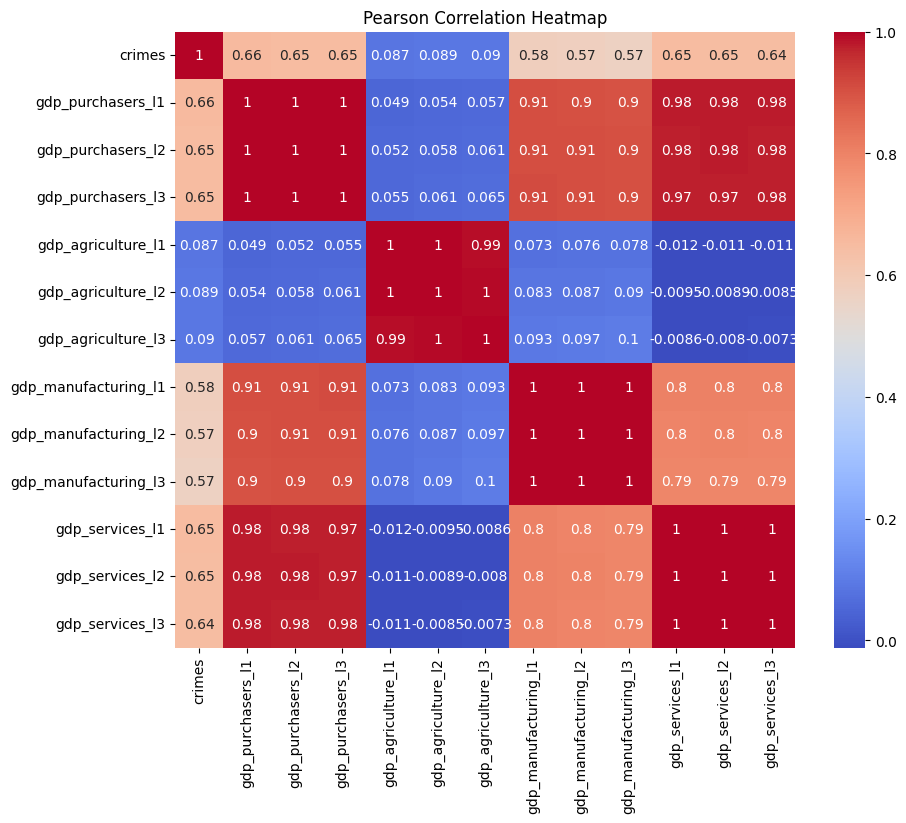

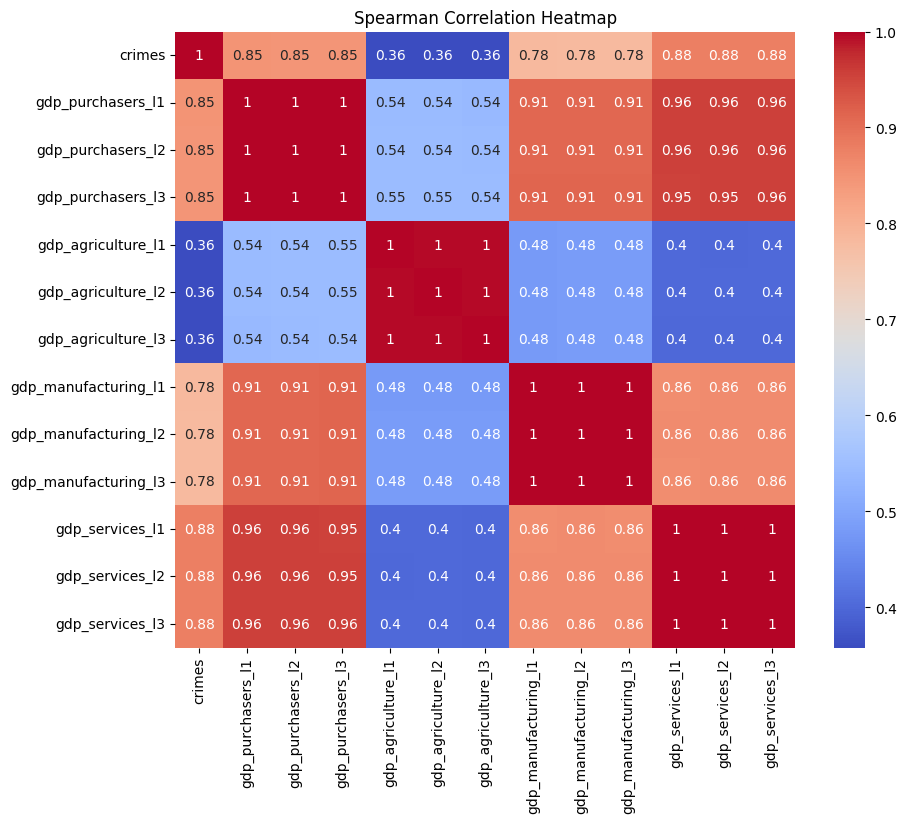

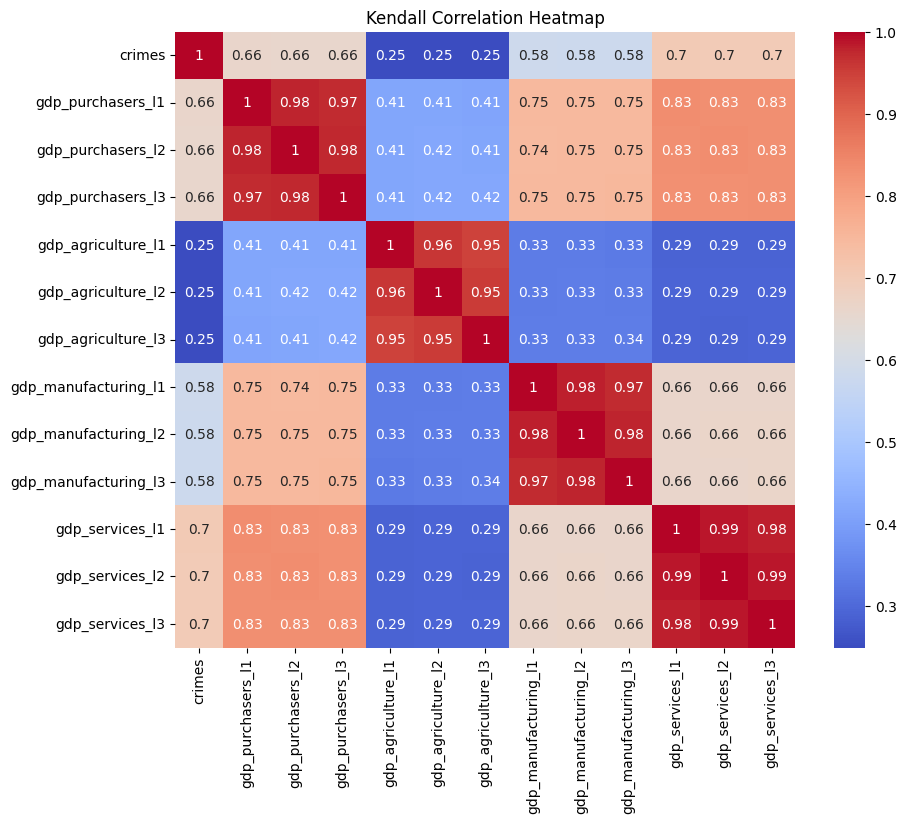

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation heatmap with different correlation types
plt.figure(figsize=(10, 8))
sns.heatmap(df_lag.corr(method='pearson'), annot=True, cmap='coolwarm')
plt.title('Pearson Correlation Heatmap')
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df_lag.corr(method='spearman'), annot=True, cmap='coolwarm')
plt.title('Spearman Correlation Heatmap')
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df_lag.corr(method='kendall'), annot=True, cmap='coolwarm')
plt.title('Kendall Correlation Heatmap')
plt.show()

In [11]:
# From the correlation analysis,
# We see strong correlations in purchasers, manufacturing, and services.
# We see weak correlation in agriculture
# We see that the immediate last year has a stronger correlation 
#  than the years before that. However, there is little difference.
# There is a perfect correlation between independent variables in the same gdp_type
#  e.g. gdp_purchasers_l1, and gdp_purchasers_l2 have a correlation 1, 
#  hence, one or the other should be removed.
# There is also strong correlation between gdp_types
#  e.g. gdp_purchasers_l1 is strongly correlated to gdp_manufacturing and gdp_services
#  hence, in this case, we engineer a combined variable through Principal Component Analysis.

In [12]:
df_lag = df_lag.drop(columns=['gdp_purchasers_l2', 'gdp_purchasers_l3',
                              'gdp_agriculture_l1','gdp_agriculture_l2',
                              'gdp_agriculture_l3', 'gdp_manufacturing_l2',
                              'gdp_manufacturing_l3', 'gdp_services_l2',
                              'gdp_services_l3'])

In [13]:
import pandas as pd
from sklearn.decomposition import PCA

# Remove L2 and L3 features
selected_features = ['gdp_purchasers_l1', 'gdp_services_l1', 'gdp_manufacturing_l1']
X = df_lag[selected_features]  # Extract selected features

# Apply PCA to reduce to 1 component
n_components = 1
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X)

# Add the PCA combined feature back to the DataFrame
df_lag['gdp_combined_pca'] = X_pca[:, 0]
# Get the PCA weights (loadings) for the first principal component
weights = pca.components_[0]  # Eigenvector corresponding to PC1

# Print the weights
for feature, weight in zip(selected_features, weights):
    print(f"Weight for {feature}: {weight:.4f}")

# Compute the gdp_combined_pca manually
df_lag['gdp_combined_pca'] = (X @ weights).values

# Print the formula
print("\nFormula for gdp_combined_pca:")
formula = " + ".join([f"{weight:.4f} * {feature}" for feature, weight in zip(selected_features, weights)])
print(f"gdp_combined_pca = {formula}")


Weight for gdp_purchasers_l1: 0.5965
Weight for gdp_services_l1: 0.5757
Weight for gdp_manufacturing_l1: 0.5593

Formula for gdp_combined_pca:
gdp_combined_pca = 0.5965 * gdp_purchasers_l1 + 0.5757 * gdp_services_l1 + 0.5593 * gdp_manufacturing_l1


# Modelling

In [14]:
# Load feature and target
X = df_lag['gdp_combined_pca']
y = df_lag['crimes']

In [15]:
from multiprocessing import Pool
import numpy as np
import random
from sklearn.model_selection import train_test_split, KFold

# -----------------------------------------------
# Randomized Search with Refined Multiprocessing
def cross_val_score_single_param(model_class, params, X_train, y_train, k=3):
    """Evaluate a single parameter combination with cross-validation."""
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    errors = []

    for train_idx, val_idx in kf.split(X_train):
        X_tr, X_val = X_train[train_idx], X_train[val_idx]
        y_tr, y_val = y_train[train_idx], y_train[val_idx]

        model = model_class(**params)
        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)
        errors.append(np.mean((y_val - y_pred) ** 2))  # Mean Squared Error

    return np.mean(errors)

def evaluate_parameter_set(args):
    """Wrapper for parallel evaluation."""
    model_class, params, X_train, y_train, k = args
    error = cross_val_score_single_param(model_class, params, X_train, y_train, k)
    return params, error

def parallel_randomized_search(model_class, param_grid, X_train, y_train, k=3, n_trials=5, n_processes=4):
    """Perform randomized search with multiprocessing."""
    tasks = []
    for _ in range(n_trials):
        params = {k: random.choice(v) for k, v in param_grid.items()}
        tasks.append((model_class, params, X_train, y_train, k))

    with Pool(processes=n_processes) as pool:
        results = pool.map(evaluate_parameter_set, tasks)

    return min(results, key=lambda x: x[1])  # Best params with lowest error

# -----------------------------------------------
# Models and Training (Same as Before)
class LinearRegressionCustom:
    def __init__(self, lr=0.01, n_iter=500):
        self.lr = lr
        self.n_iter = n_iter
        self.weights = 0
        self.bias = 0

    def fit(self, X, y):
        n_samples = X.shape[0]
        for _ in range(self.n_iter):
            y_pred = self.weights * X + self.bias
            dw = -(2 / n_samples) * np.sum(X * (y - y_pred))
            db = -(2 / n_samples) * np.sum(y - y_pred)
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict(self, X):
        return self.weights * X + self.bias

class DecisionTreeCustom:
    def __init__(self, max_depth=3):
        self.max_depth = max_depth
        self.tree = None

    def _split(self, X, y, threshold):
        left_idx = X <= threshold
        right_idx = X > threshold
        return X[left_idx], y[left_idx], X[right_idx], y[right_idx]

    def _build_tree(self, X, y, depth):
        if depth >= self.max_depth or np.unique(y).size == 1:
            return np.mean(y)

        thresholds = np.unique(X)
        best_split, best_score = None, float("inf")
        for threshold in thresholds:
            _, y_left, _, y_right = self._split(X, y, threshold)
            score = len(y_left) * np.var(y_left) + len(y_right) * np.var(y_right)
            if score < best_score:
                best_score, best_split = score, threshold

        left_X, left_y, right_X, right_y = self._split(X, y, best_split)
        return {
            'threshold': best_split,
            'left': self._build_tree(left_X, left_y, depth + 1),
            'right': self._build_tree(right_X, right_y, depth + 1),
        }

    def fit(self, X, y):
        self.tree = self._build_tree(X.flatten(), y, 0)

    def _predict_sample(self, x, node):
        if not isinstance(node, dict):
            return node
        if x <= node['threshold']:
            return self._predict_sample(x, node['left'])
        return self._predict_sample(x, node['right'])

    def predict(self, X):
        return np.array([self._predict_sample(x, self.tree) for x in X.flatten()])

# -----------------------------------------------
# Simulate Data and Execute
X = np.random.rand(100, 1) * 10
y = 3 * X.flatten() + np.random.randn(100) * 2  # Linear target with noise

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Linear Regression Search
linear_params = {'lr': [0.001, 0.01, 0.1], 'n_iter': [100, 500, 1000]}
best_linear_params, linear_error = parallel_randomized_search(
    LinearRegressionCustom, linear_params, X_train, y_train, k=3, n_trials=5, n_processes=4
)

# Decision Tree Search
tree_params = {'max_depth': [2, 3, 5]}
best_tree_params, tree_error = parallel_randomized_search(
    DecisionTreeCustom, tree_params, X_train, y_train, k=3, n_trials=5, n_processes=4
)

# Output Results
print("Best Linear Regression Parameters:", best_linear_params)
print("Linear Regression Cross-Validation Error:", linear_error)

print("\nBest Decision Tree Parameters:", best_tree_params)
print("Decision Tree Cross-Validation Error:", tree_error)
